# Practice 3 — Getting started with Hugging Face

**Môn Deep Learning — UTH.** Thực hiện đề giảng viên: (1) dùng mô hình sentiment pretrained, tokenize và suy luận; (2) tải dữ liệu nhị phân, tiền xử lý, cấu hình `Trainer`, fine-tune và đánh giá.

Notebook dùng chung mã nguồn với CLI. Mặc định **`MODE="view"`**: đọc và kiểm tra artifacts Kaggle có trong repo, không tải model/dataset và không train lại. Đổi thành **`"train"`** khi chủ động thực hiện thí nghiệm mới trên GPU. Các output lưu trong notebook này được thực thi ở chế độ view từ bằng chứng Kaggle; đây không phải lần GPU training mới trên máy tạo báo cáo.

Cài `labs/lab03/requirements.txt` trong Python 3.12 trước khi mở notebook. Hướng dẫn môi trường và sử dụng mô hình nằm trong `labs/lab03/README.md`.

In [1]:
from pathlib import Path
import sys
import json

LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
if LAB is None:
    raise RuntimeError("Open this notebook inside the Lab-DL repository")
sys.path.insert(0, str(LAB.parents[1]))

import pandas as pd
from IPython.display import display, Image, Markdown
from labs.lab03.src.workflow import read_config, exercise1, finetune
from labs.lab03.src.evidence import selected_run, audit_exercise1, audit_finetuning, read_json

# view: đọc và xác minh kết quả Kaggle đã lưu, không cần mạng/GPU.
# train: tạo thí nghiệm mới; Exercise 2 mặc định yêu cầu CUDA.
MODE = "view"
assert MODE in {"view", "train"}
config = read_config()
print("MODE:", MODE)
print("Lab directory:", LAB)
print("View outputs are from Kaggle artifacts, not a new training run.")

/workspace/lab03-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MODE: view
Lab directory: /workspace/Lab-DL/labs/lab03
View outputs are from Kaggle artifacts, not a new training run.


## Exercise 2 — Fine-tuning DistilBERT trên toàn bộ Rotten Tomatoes

Dùng các split chính thức: **8.530 train, 1.066 validation, 1.066 test**. Không lấy subset và không chia lại validation. Train cập nhật tham số; validation chọn best checkpoint; test đánh giá cuối và không được dùng để chọn siêu tham số.

Backbone `distilbert/distilbert-base-uncased` được tải mới với đầu phân loại hai lớp. Optimizer AdamW, cross-entropy loss. Sanity overfit chỉ chạy trên mô hình disposable trong tests, không tác động trọng số train chính.

In [2]:
if MODE == "train":
    finetuning_run = finetune(config)
else:
    finetuning_run = selected_run("finetuning")

finetuning_audit = audit_finetuning(finetuning_run)
print("Selected run:", finetuning_run.name)
print("Manifest files verified:", finetuning_audit["verified_files"])
print("Weights available locally:", finetuning_audit["checkpoint_available_locally"])
print("Checkpoint evidence:", finetuning_audit["checkpoint_verification"])

Selected run: 20261025T181550Z_finetuning_e02bced7
Manifest files verified: 18
Weights available locally: False
Checkpoint evidence: Kaggle reload_check.json; weights are not re-executed by this audit


### Dữ liệu, môi trường và tiền xử lý

Tokenizer WordPiece thêm special tokens, truncation ở 128; `DataCollatorWithPadding` đệm theo batch để tránh lãng phí. Run Kaggle ghi độ dài train trung bình 27,37 tokens, tối đa 78 và tỉ lệ truncation 0%; thống kê này chỉ mô tả train.

`input_ids` và `attention_mask` có shape `(B,S)`; logits `(B,2)`. Labels là 0 (Negative), 1 (Positive). Seed 42; FP16 chỉ khi CUDA có sẵn.

In [3]:
run_config = read_json(finetuning_run / "config.json")
statistics = read_json(finetuning_run / "data_statistics.json")
display(pd.DataFrame([statistics["split_sizes"]], index=["Official split size"]))
display(pd.DataFrame([statistics["train_token_lengths"]]))
display(pd.DataFrame([run_config["exercise2"]]))
display(read_json(finetuning_run / "environment_snapshot.json"))

,train,validation,test
Official split size,8530,1066,1066


,mean,max,truncated_fraction
0,27.368347,78,0.0


,dataset_name,dataset_revision,model_name,model_revision,max_length,batch_size,eval_batch_size,learning_rate,num_train_epochs,weight_decay,warmup_ratio,fp16
0,cornell-movie-review-data/rotten_tomatoes,main,distilbert/distilbert-base-uncased,main,128,16,32,0.00002,3,0.01,0.1,True


{'python': '3.12.15 (main, Oct 21 2026, 17:47:06) [Clang 23.1.3 ]',
 'platform': 'Linux-6.18.55+-x86_64-with-glibc2.39',
 'cuda_available': True,
 'device': 'Tesla T4',
 'versions': {'torch': '2.6.0',
  'transformers': '4.48.3',
  'datasets': '3.2.0',
  'evaluate': '0.4.3',
  'accelerate': '1.3.0',
  'numpy': '2.2.2',
  'scikit-learn': '1.6.1'}}

### Lịch huấn luyện và lựa chọn checkpoint

3 epochs; train/eval batch 16/32; LR `2e-5`; warmup ratio `0.1`; weight decay `0.01`. Đánh giá/lưu mỗi epoch, khôi phục checkpoint có validation accuracy tốt nhất.

Phân biệt: `loss` là trung bình loss trong quá trình tối ưu của epoch; `train_loss` tại lần evaluate là loss khi model ở eval mode trên train. Hai đại lượng không nhất thiết bằng nhau.

In [4]:
history = read_json(finetuning_run / "trainer_history.json")
epoch_rows = []
for row in history:
    if "eval_accuracy" in row:
        epoch = row["epoch"]
        train_eval = next(r for r in history if r.get("epoch") == epoch and "train_accuracy" in r)
        train_log = next(r for r in history if r.get("epoch") == epoch and "loss" in r)
        epoch_rows.append({"epoch": epoch, "step": row["step"], "optimization_loss": train_log["loss"],
            "train_eval_loss": train_eval["train_loss"], "train_accuracy": train_eval["train_accuracy"],
            "validation_loss": row["eval_loss"], "validation_accuracy": row["eval_accuracy"]})
display(pd.DataFrame(epoch_rows))
print("Best validation epoch:", finetuning_audit["best_validation_epoch"])
print("Training summary:", read_json(finetuning_run / "train_metrics.json"))

,epoch,step,optimization_loss,train_eval_loss,train_accuracy,validation_loss,validation_accuracy
0,1.0,534,0.4609,0.293893,0.880774,0.403606,0.822702
1,2.0,1068,0.2597,0.126099,0.959789,0.378666,0.841463
2,3.0,1602,0.1515,0.093490,0.972098,0.489638,0.843340


Best validation epoch: 3.0
Training summary: {'train_runtime': 95.9321, 'train_samples_per_second': 266.751, 'train_steps_per_second': 16.699, 'total_flos': 323059008078528.0, 'train_loss': 0.2907267128781284, 'epoch': 3.0}


### Đánh giá test và kiểm tra độc lập

Metrics được tính lại từ toàn bộ `all_predictions.json`, đối chiếu `test_metrics.json` ở sai số `1e-12`; kiểm tra indices 0..1065, 533 mẫu mỗi lớp, xác suất hợp lệ và nhãn argmax. Audit này không chạy lại checkpoint.

Binary Precision/Recall/F1 dùng lớp Positive làm positive class. Macro metrics lấy trung bình đều giữa hai lớp.

In [5]:
display(pd.DataFrame([finetuning_audit["metrics"]]))
display(pd.DataFrame(finetuning_audit["classification_report"]).T)
print("Correct:", finetuning_audit["correct"], "Incorrect:", finetuning_audit["incorrect"])
print("Confusion matrix [TN FP; FN TP]:", finetuning_audit["confusion_matrix"])

,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,0.839587,0.835185,0.846154,0.840634,0.839646,0.839587,0.83958


,precision,recall,f1-score,support
NEGATIVE,0.844106,0.833021,0.838527,533.000000
POSITIVE,0.835185,0.846154,0.840634,533.000000
accuracy,0.839587,0.839587,0.839587,0.839587
macro avg,0.839646,0.839587,0.839580,1066.000000
weighted avg,0.839646,0.839587,0.839580,1066.000000


Correct: 895 Incorrect: 171
Confusion matrix [TN FP; FN TP]: [[444, 89], [82, 451]]


In [6]:
import numpy as np
cm = np.array(finetuning_audit["confusion_matrix"])
per_class = []
for i, label in enumerate(["NEGATIVE", "POSITIVE"]):
    tp = int(cm[i, i])
    fn = int(cm[i].sum()) - tp
    fp = int(cm[:, i].sum()) - tp
    tn = int(cm.sum()) - tp - fn - fp
    report = finetuning_audit["classification_report"][label]
    per_class.append({"label": label, "precision": report["precision"],
        "recall_TPR": tp / (tp + fn), "F1": report["f1-score"],
        "FPR": fp / (fp + tn), "support": report["support"]})
display(pd.DataFrame(per_class))
print("Test loss: not logged in the original Kaggle evaluation artifacts.")

,label,precision,recall_TPR,F1,FPR,support
0,NEGATIVE,0.844106,0.833021,0.838527,0.153846,533.0
1,POSITIVE,0.835185,0.846154,0.840634,0.166979,533.0


Test loss: not logged in the original Kaggle evaluation artifacts.


### Năm biểu đồ từ run Kaggle

Learning curves giúp phát hiện overfitting; confusion matrix hiển thị số lượng và phần trăm theo hàng; metrics bar hiển thị binary metrics; token distribution đo trước truncation; bảng dự đoán ưu tiên ví dụ đúng/sai có confidence cao nên không phải mẫu ngẫu nhiên đại diện.

learning_curves.png


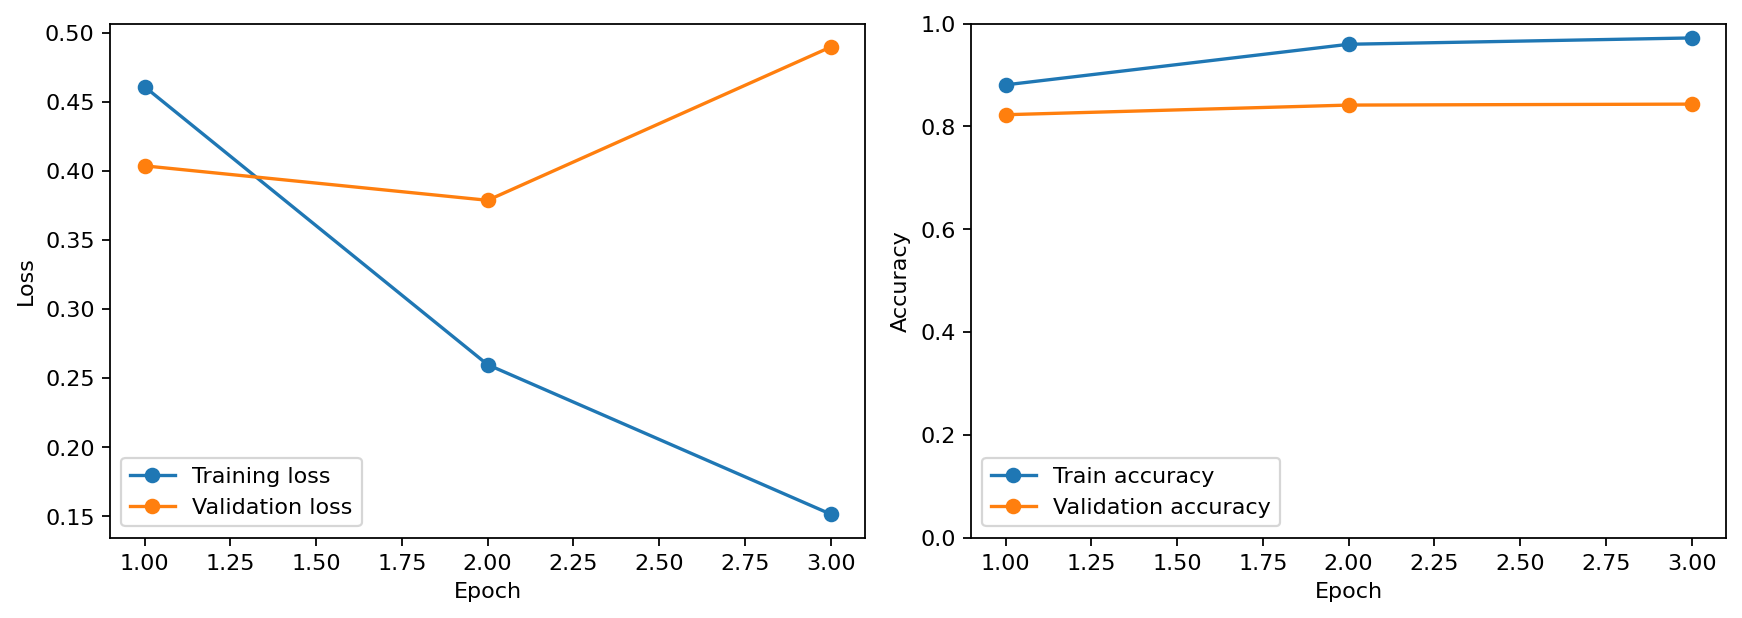

confusion_matrix.png


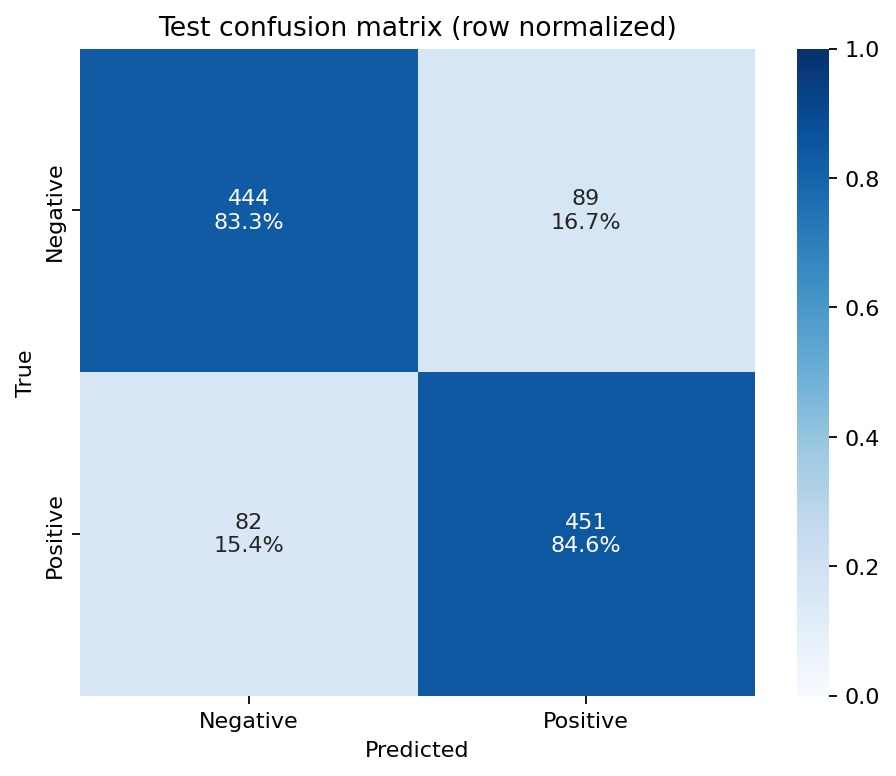

metrics_bar.png


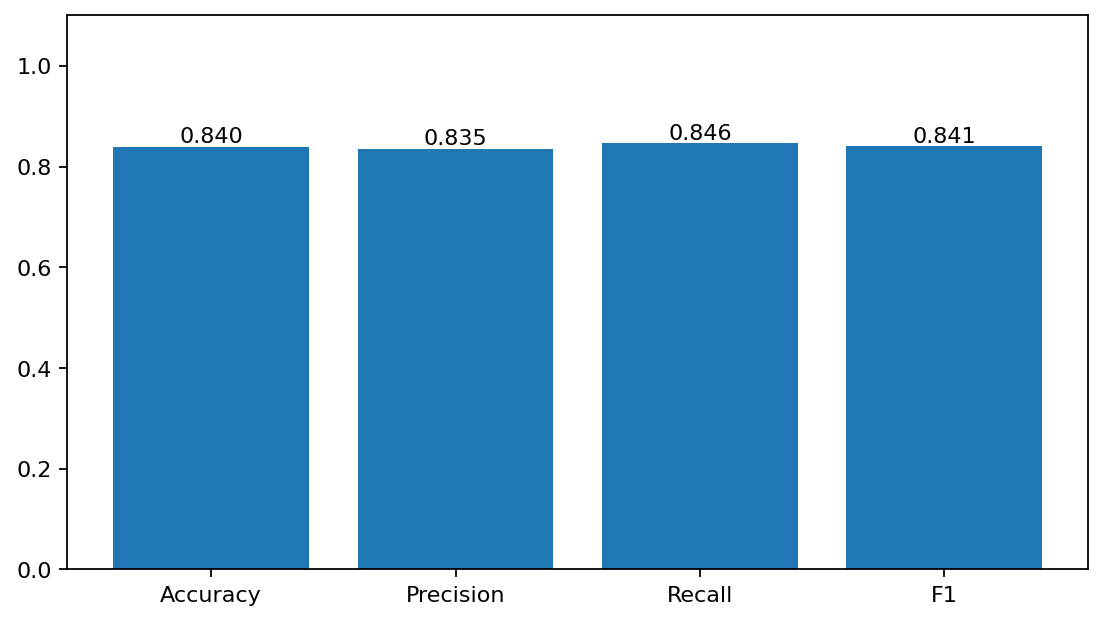

token_length_distribution.png


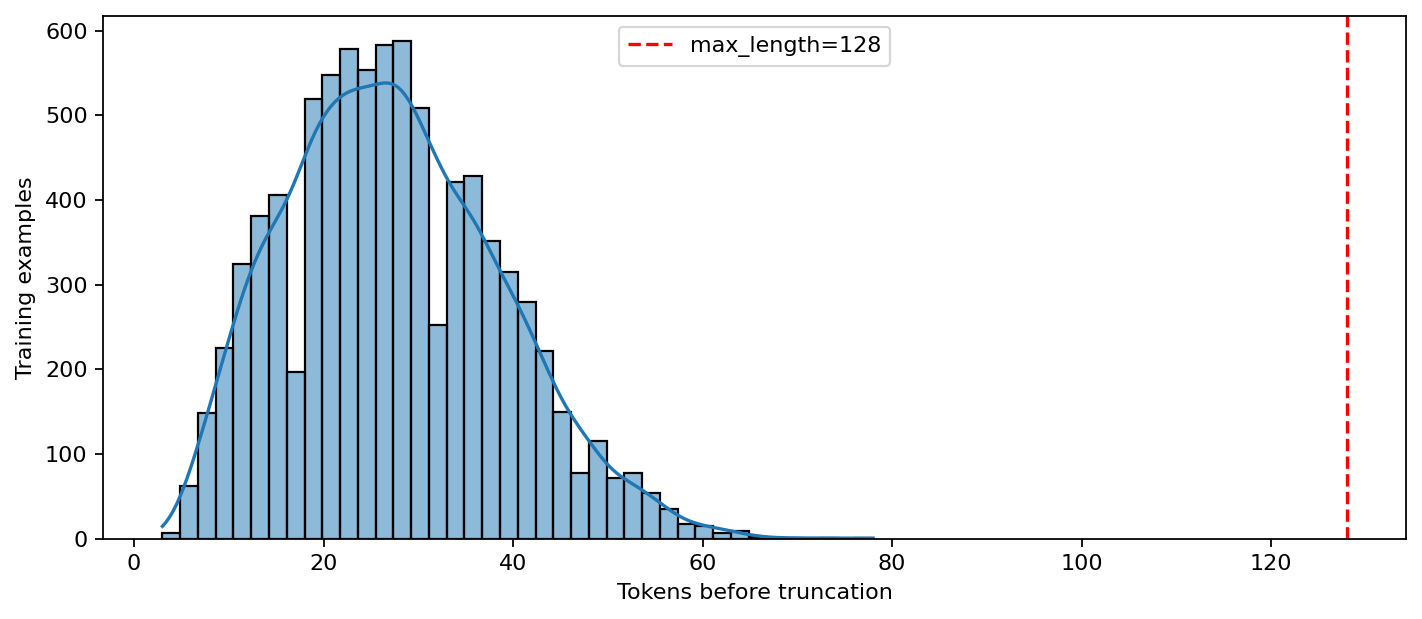

sample_predictions.png


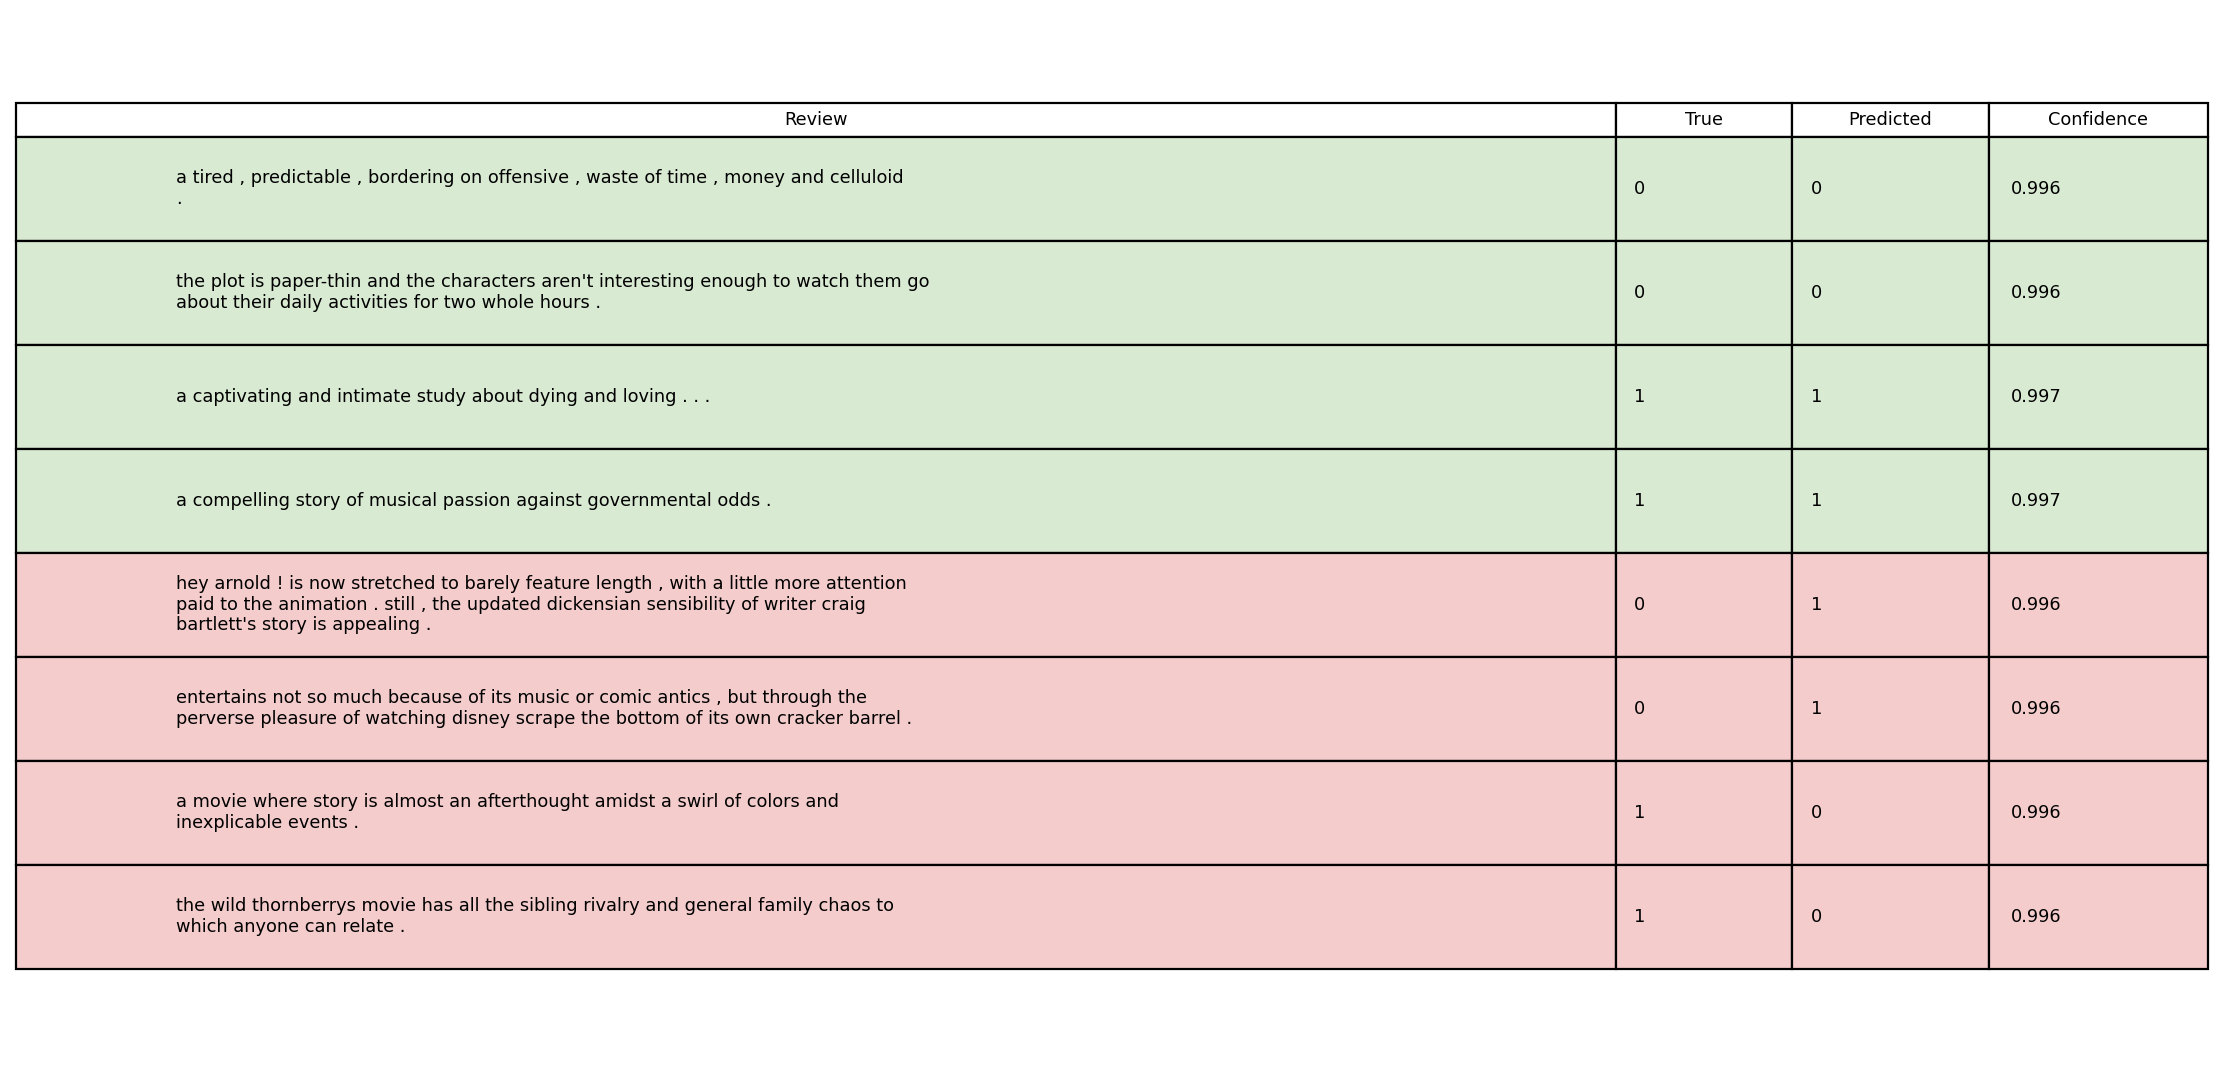

In [7]:
for filename in ["learning_curves.png", "confusion_matrix.png", "metrics_bar.png",
                 "token_length_distribution.png", "sample_predictions.png"]:
    print(filename)
    display(Image(filename=str(finetuning_run / filename)))

### Phân tích lỗi và diễn giải kết quả

Run Kaggle tham chiếu `20261025T181550Z_finetuning_e02bced7` đạt Accuracy **83,96%** và Binary F1 **84,06%**, đúng 895/1.066 mẫu. Train accuracy tăng lên 97,21% trong khi validation chỉ 84,33%. Validation loss tăng từ 0,3787 lên 0,4896 ở epoch 3: dấu hiệu overfitting; epoch 3 vẫn được chọn theo accuracy, không theo loss.

Các ví dụ sai:
- **Hey Arnold:** “barely feature length” mang tính chê, nhưng “appealing” và lời khen phần hình ảnh có thể làm tín hiệu tích cực lấn át. Đây là giả thuyết đọc câu.
- **Disney:** cấu trúc “entertains not so much … but … scrape the bottom …” thể hiện sắc thái mỉa mai; từ “entertains” riêng lẻ không đủ quyết định nhãn.
- **“story is almost an afterthought”:** các từ mang vẻ chê có thể nằm trong lời đánh giá trải nghiệm thị giác được dataset gán tích cực. Không tự kết luận nhãn dataset sai.
- **The Wild Thornberrys:** “rivalry”, “chaos” mô tả xung đột, còn “anyone can relate” thể hiện đồng cảm tích cực.

Confidence ~99,6% trên các lỗi cho thấy có dự đoán tự tin nhưng sai; chưa đủ để kết luận hiệu chuẩn trên toàn dataset. Không suy ra nguyên nhân bên trong mô hình từ vài từ khóa.

In [8]:
display(pd.DataFrame(read_json(finetuning_run / "sample_predictions.json")))
print("Recorded checkpoint reload check (executed on Kaggle):")
display(read_json(finetuning_run / "reload_check.json"))

,index,text,true_label,predicted_label,confidence
0,823,"a tired , predictable , bordering on offensive...",0,0,0.996413
1,1017,the plot is paper-thin and the characters aren...,0,0,0.996322
2,85,a captivating and intimate study about dying a...,1,1,0.997054
3,465,a compelling story of musical passion against ...,1,1,0.997025
4,1014,hey arnold ! is now stretched to barely featur...,0,1,0.996078
5,939,entertains not so much because of its music or...,0,1,0.995826
6,219,a movie where story is almost an afterthought ...,1,0,0.995609
7,470,the wild thornberrys movie has all the sibling...,1,0,0.995609


Recorded checkpoint reload check (executed on Kaggle):


{'weights_exact_match': True,
 'execution': 'CPU FP32, clean forward methods',
 'predictions': [{'text': 'lovingly photographed in the manner of a golden book sprung to life , stuart little 2 manages sweetness largely without stickiness .',
   'label': 'POSITIVE',
   'score': 0.9718583226203918,
   'probabilities': [0.02814166434109211, 0.9718583226203918]}]}

### Kết luận và giới hạn

Đã thực hiện đủ quy trình đề bài với official splits, Trainer và đánh giá độc lập. Kết quả dưới 85% vẫn đáp ứng đề vì giảng viên không đặt ngưỡng này. Không chọn lại mô hình dựa trên test.

Trọng số đã huấn luyện được lưu riêng; hướng dẫn khôi phục và đánh giá lại có trong README. Notebook ở chế độ view trình bày kết quả đã lưu, không thực hiện lại huấn luyện hoặc tải lại trọng số.